# 02. 피처 만들기

안녕하세요! **KBO 승패 예측 프로젝트의 두 번째 이야기**예요.
01번 노트북에서 믿을 만한 경기 기록(2015~2026년)을 모았으니, 이번에는 그 기록을 모델이 배울 수 있는 **피처**(feature: 모델에 넣는 입력 숫자 하나하나, 예를 들어 "두 팀의 승률 차이")로 바꿔 볼게요.

### 이 노트북이 하는 일
- "경기 **전**에 알 수 있는 정보만 쓴다"는 규칙이 무슨 뜻인지, 실제 경기(2025-05-10 삼성 vs LG 더블헤더)로 보여 드려요.
- 한 팀(2025 LG)의 기록이 경기를 치를 때마다 어떻게 쌓이는지 표로 따라가 봐요.
- 경기마다 만드는 피처 **26개**를 사전처럼 정리해요(이름·뜻·계산식·왜 넣었나).
- 선발투수 피처를 어떻게 만드는지 한 경기 예시로 보여 드려요.
- 2015~2026년 전체 데이터셋(**8,465경기**)을 만들고, 피처와 승패의 관계를 그래프 3개로 확인해요.
- 마지막으로 결과를 파일(parquet)로 저장하고, 모델이 학습에 쓴 파일과 **한 글자도 다르지 않은지** 지문(SHA256)으로 검사해요.

### 왜 필요한가요?
모델은 숫자만 볼 수 있어요. "LG가 요즘 잘 나간다", "오늘 선발이 에이스다" 같은 이야기를 숫자로 바꿔 줘야 배울 수 있죠.
그런데 이때 가장 조심해야 할 함정이 **누수**(leakage: 예측하려는 경기의 결과나 그 뒤의 정보가 입력에 몰래 섞여 들어가는 것)예요.
누수가 있으면 연습 때는 성적이 아주 좋아 보이지만, 실제로 내일 경기를 예측할 때는 그 정보가 없으니 성적이 뚝 떨어져요.
그래서 이 노트북의 절반은 "**우리 피처에는 누수가 없다**"를 눈으로 확인하는 데 써요.

### 짝이 되는 `.py` 파일
이 노트북도 계산을 직접 새로 짜지 않고 `src/kbo_predict/`의 코드를 **불러서 쓰기만** 해요. 그래서 노트북 결과와 매일 도는 자동 예측(GitHub Actions)의 결과가 언제나 같아요.

| 파일 | 하는 일 |
|---|---|
| `features.py` | 리그 상태(`LeagueState`)를 경기 순서대로 쌓고, 경기마다 피처 26개를 계산하고(`game_features`), 전체 데이터셋을 만들어 저장해요(`build_dataset`, `save_features`) |
| `raw_store.py` | 01번에서 모아 둔 경기 목록·박스스코어·예고 선발을 불러와요 |
| `seasons.py` | 시즌별 정규시즌 날짜 범위(`is_regular`)를 알려 줘요 |
| `scripts/run_pipeline.py` | 매일 라이브 예측이 "오늘 경기 직전" 상태를 만드는 `build_state`가 들어 있어요. 이 노트북에서도 같은 함수를 써요 |

### 읽는 순서
1. 준비
2. "경기 전 정보만"의 뜻 — 누수 예시
3. 팀 기록이 쌓이는 모습 (2025 LG 개막 10경기)
4. 피처 26개 사전
5. 선발투수 피처
6. 전체 데이터셋 만들기 (2015~2026)
7. 피처와 승패의 관계 (그래프 3개)
8. 파일로 저장하고 지문(SHA256) 확인
9. 요약과 다음 이야기

> 결과만 궁금하시면 4번(피처 사전), 6번(데이터셋), 7번(그래프)만 보셔도 충분해요.
> 이 노트북은 인터넷 없이 끝까지 실행돼요(30초 안팎이면 끝나요).

## 1. 준비

01번 노트북과 같은 준비 셀이에요.

- 이 노트북은 `notebooks/` 폴더에서 실행되니까, 한 단계 위(`Path.cwd().parent`)가 프로젝트 루트예요.
- `src/`를 파이썬 경로에 넣어서 `kbo_predict` 패키지를, 루트를 넣어서 `scripts/` 폴더를 불러올 수 있게 해요.
- `KBO_DATA_DIR` 환경변수로 데이터 폴더(`data/`)를 알려 줘요. `raw_store`가 이 값을 보고 파일을 찾아요.
- 그래프의 한글이 깨지지 않도록 한글 폰트를 지정해요.

**출력 보는 법:** 저장된 시즌 목록(2015~2026)과 피처 개수(26)가 보이면 준비 끝이에요.

In [1]:
import copy
import json
import logging
import os
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent                                   # notebooks/의 한 단계 위 = 프로젝트 루트
sys.path.insert(0, str(ROOT / "src"))                      # kbo_predict 패키지를 불러오기 위해
sys.path.insert(0, str(ROOT))                              # scripts/ 폴더를 불러오기 위해
os.environ.setdefault("KBO_DATA_DIR", str(ROOT / "data"))  # raw_store가 데이터를 찾는 폴더

# 그래프 한글 폰트: 윈도우 → 맥 → 리눅스(나눔) → 기본 폰트 순으로 있는 것을 써요
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False                 # 마이너스 기호가 네모로 깨지지 않게
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # 없는 후보 폰트 안내 메시지는 숨겨요
pd.set_option("display.width", 120)
pd.set_option("display.max_rows", 40)

from kbo_predict import features, raw_store
from kbo_predict.seasons import is_regular
from scripts.run_pipeline import build_state

print("저장된 시즌:", raw_store.available_seasons())
print("피처 개수  :", len(features.FEATURE_NAMES),
      f"(팀 {len(features.TEAM_FEATURES)}개 + 선발투수 {len(features.STARTER_FEATURES)}개)")

저장된 시즌: [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
피처 개수  : 26 (팀 19개 + 선발투수 7개)


## 2. "경기 전 정보만"의 뜻 — 누수 예시

### 규칙 하나
> **어떤 경기의 피처는 '그 경기 날짜의 전날까지' 끝난 경기로만 만든다.**

예를 들어 2025년 5월 10일(토)에는 대구에서 **삼성(홈) vs LG(원정) 더블헤더**(같은 두 팀이 하루에 두 경기를 연달아 치르는 것)가 있었어요.
두 경기의 피처를 만들 때 쓸 수 있는 정보를 시간 순서로 놓으면 이래요.

| 시점 | 무슨 일이 있었나 | 두 경기의 피처에 들어가나요? |
|---|---|---|
| 3/22(개막) ~ 5/9 | 이미 끝난 정규시즌 경기들 | ✅ 들어가요 |
| 5/10 1차전 (game_id 13007) | LG 5 : 4 삼성 — **우리가 맞히려는 결과** | ❌ 정답 그 자체라서 안 돼요 |
| 5/10 2차전 (game_id 13011) | 1차전이 끝난 뒤 시작 — LG 4 : 1 삼성 | ❌ 1차전 결과도 2차전 피처에 넣지 않아요 |
| 5/11 이후 | 미래 | ❌ |

2차전이 시작될 때는 1차전 결과를 이미 알 수 있는데, 왜 넣지 않을까요?
라이브 예측은 **하루에 한 번, 그날 첫 경기 전에** 그날 모든 경기를 예측해요. 그 시점에는 1차전 결과가 없어요.
학습할 때도 똑같은 조건을 만들어 줘야 "연습 성적 = 실전 성적"이 돼요. 그래서 `build_training_frame`은 **하루치 경기의 피처를 모두 계산한 다음에야** 그날 결과를 상태에 반영해요.

### 직접 확인하기
`build_state(2025, "2025-05-10")`는 매일 라이브 예측이 쓰는 바로 그 함수예요. 직전 시즌(2024) 정규시즌 전체와 2025 시즌 **5월 9일까지**의 경기를 순서대로 `LeagueState`에 쌓아 줘요.
그 상태로 두 경기의 피처를 `game_features`로 계산해요(선발투수는 박스스코어에서 찾는데, 5번에서 자세히 이야기해요).

**출력 보는 법:** 행 하나가 피처 하나예요. 맨 오른쪽 `팀 피처 같음?`이 팀 피처 19개에서 모두 `True`면, 2차전 피처에 1차전 결과가 섞이지 않았다는 뜻이에요.
선발투수 피처(아래 7줄)는 두 경기 선발이 달라서 값이 달라요.

In [2]:
games25 = {g["game_id"]: g for g in raw_store.load_games(2025)}
box25 = raw_store.load_boxscores(2025)
G1, G2 = 13007, 13011  # 2025-05-10 삼성(홈) vs LG(원정) 더블헤더 1·2차전

state = build_state(2025, "2025-05-10")  # 2024 시즌 전체 + 2025-05-09까지 쌓은 리그 상태
f1 = features.game_features(games25[G1], state, features.starter_ids(box25[G1]))
f2 = features.game_features(games25[G2], state, features.starter_ids(box25[G2]))

dh = pd.DataFrame({"1차전 13007": [f1[k] for k in features.FEATURE_NAMES],
                   "2차전 13011": [f2[k] for k in features.FEATURE_NAMES]},
                  index=features.FEATURE_NAMES).round(3)
dh["팀 피처 같음?"] = [dh.loc[k, "1차전 13007"] == dh.loc[k, "2차전 13011"] if k in features.TEAM_FEATURES else "-"
                    for k in dh.index]
display(dh)
print("팀 피처 19개가 1·2차전에서 모두 같나요?:", all(f1[k] == f2[k] for k in features.TEAM_FEATURES))

,1차전 13007,2차전 13011,팀 피처 같음?
win_pct_diff,-0.108,-0.108,True
last10_diff,0.100,0.100,True
run_diff_diff,-0.977,-0.977,True
pyth_diff,-0.115,-0.115,True
prev_season_diff,0.014,0.014,True
obp_diff,0.001,0.001,True
hr_rate_diff,0.008,0.008,True
k_rate_diff,0.009,0.009,True
bb_rate_diff,-0.015,-0.015,True
era_diff,1.115,1.115,True


팀 피처 19개가 1·2차전에서 모두 같나요?: True


**해석:** 팀 피처 19개가 두 경기에서 똑같아요. 예를 들어 `win_pct_diff`(승률 차이, 홈 − 원정)는 둘 다 −0.108이에요. 5월 9일까지 삼성 승률 .514, LG 승률 .622였으니까 0.514 − 0.622 = −0.108이죠.
1차전에서 LG가 이겼지만, 그 결과는 2차전 피처에 들어가지 않았어요.

### 만약 규칙을 어기면? (누수가 생긴 모습)
비교를 위해 일부러 잘못된 상태를 만들어 볼게요. 5월 9일까지의 상태를 복사한 뒤 **5월 10일 경기 결과까지** 넣고(`update`) 1차전 피처를 다시 계산해요.
이건 "정답을 미리 보고 시험을 치는" 것과 같아요.

**출력 보는 법:** 왼쪽이 올바른 값, 오른쪽이 누수가 생긴 값이에요. 값이 달라진 피처만 보여 드려요.

In [3]:
leaky = copy.deepcopy(state)               # 원래 상태는 그대로 두고 복사본에만 넣어요
for g in games25.values():
    if g["date"] == "2025-05-10":
        leaky.update(g, box25.get(g["game_id"]))   # ← 하면 안 되는 일: 예측할 날의 결과를 미리 반영
f1_leak = features.game_features(games25[G1], leaky, features.starter_ids(box25[G1]))

leak_cmp = pd.DataFrame({"올바름(5/9까지)": [f1[k] for k in features.FEATURE_NAMES],
                         "누수(5/10 결과 포함)": [f1_leak[k] for k in features.FEATURE_NAMES]},
                        index=features.FEATURE_NAMES).round(3)
display(leak_cmp[leak_cmp.iloc[:, 0] != leak_cmp.iloc[:, 1]])

,올바름(5/9까지),누수(5/10 결과 포함)
win_pct_diff,-0.108,-0.154
last10_diff,0.100,-0.300
run_diff_diff,-0.977,-1.128
pyth_diff,-0.115,-0.129
obp_diff,0.001,-0.003
hr_rate_diff,0.008,0.007
k_rate_diff,0.009,0.011
bb_rate_diff,-0.015,-0.014
era_diff,1.115,1.187
fip_diff,0.480,0.495


**해석:** 누수가 생기면 26개 중 22개가 달라져요. 특히 `win_pct_diff`가 −0.108 → −0.154로, `h2h_home_pct`(올 시즌 두 팀 **맞대결**에서 홈팀 삼성의 승률)가 .333 → .200으로 내려갔어요.
삼성이 그날 두 번 진 결과가 피처에 미리 들어가서 "삼성이 질 것 같다"는 쪽으로 기울어진 거예요. 모델은 이런 피처로 배우면 연습 때만 똑똑해 보여요.

이 노트북 6번에서 전체 데이터셋을 만든 뒤, 데이터셋에 들어간 13007·13011번 행이 **위의 올바른 값과 똑같은지** 한 번 더 확인할게요.

## 3. 팀 기록이 쌓이는 모습 — 2025 LG 개막 10경기

`LeagueState`는 경기가 끝날 때마다 팀별 기록을 더해 가는 **누적 장부**예요. 장부에서 "이 날짜 경기 직전" 요약을 꺼내는 게 `team_line(팀, 날짜)`예요.
2025년 LG 트윈스의 **개막(3월 22일)부터 10경기** 동안 경기 직전 장부가 어떻게 바뀌는지 따라가 볼게요. 개막부터 봐야 "처음엔 비어 있다가 채워지는" 모습이 잘 보여요.

표의 칸은 이런 뜻이에요(모두 **그 경기 직전**까지의 올 시즌 기록이에요).

| 칸 | 뜻 |
|---|---|
| `승률` | 승 ÷ (승 + 패). 무승부는 빼고 계산해요 |
| `최근10` | 최근 10경기(무승부 제외) 중 이긴 비율 |
| `경기당 득실차` | (낸 점수 − 내준 점수) ÷ 경기 수. 승률보다 운이 덜 섞인 실력 지표예요 |
| `피타고리안` | **피타고리안 기대 승률**: 득점^1.83 ÷ (득점^1.83 + 실점^1.83). "이만큼 점수를 내고 내줬으면 보통 이 정도 승률이 나온다"는 값이에요(원래 지수가 2라서 피타고라스 정리를 닮아 붙은 이름이에요) |
| `출루율` | **OBP**(On-Base Percentage): 타자가 타석에서 안타·볼넷·몸에 맞는 공으로 1루 이상 살아 나간 비율 |
| `팀 ERA` | **평균자책점**(Earned Run Average): 투수진이 9이닝(한 경기)당 내준 자책점. 낮을수록 좋아요 |
| `휴식일` | 이 경기 날짜 − 마지막 경기 날짜(일). 1이면 어제도 경기를 했다는 뜻이에요 |
| `결과` | 그날 LG의 승패 — **피처가 아니라 정답**이에요. 다음 줄의 장부에만 반영돼요 |

**출력 보는 법:** 한 줄 = LG의 한 경기예요. 위에서 아래로 내려가며 숫자가 어떻게 바뀌는지 보세요. `NaN`은 "아직 계산할 수 없음"(Not a Number, 빈 값)이에요.

In [4]:
g25 = pd.DataFrame(raw_store.load_games(2025))
g25["regular"] = [is_regular(2025, date.fromisoformat(d), gid) for d, gid in zip(g25["date"], g25["game_id"])]
lg_games = g25[g25["regular"] & (g25["status"] == "FINAL")
               & ((g25["home_code"] == "LG") | (g25["away_code"] == "LG"))].head(10)

lg_rows = []
for g in lg_games.to_dict("records"):
    line = build_state(2025, g["date"]).team_line("LG", g["date"])  # 그 경기 직전의 LG 장부
    at_home = g["home_code"] == "LG"
    lg_runs, opp_runs = (g["home_score"], g["away_score"]) if at_home else (g["away_score"], g["home_score"])
    lg_rows.append({
        "날짜": g["date"], "상대": g["away_code"] if at_home else g["home_code"], "장소": "홈" if at_home else "원정",
        "치른 경기": line["games"], "승률": line["win_pct"], "최근10": line["last10"],
        "경기당 득실차": line["run_diff"], "피타고리안": line["pyth"], "출루율": line["obp"],
        "팀 ERA": line["era"], "휴식일": line["rest_days"],
        "결과": f"{'승' if lg_runs > opp_runs else '패'} {int(lg_runs)}:{int(opp_runs)}",
    })
display(pd.DataFrame(lg_rows).round(3))

,날짜,상대,장소,치른 경기,승률,최근10,경기당 득실차,피타고리안,출루율,팀 ERA,휴식일,결과
0,2025-03-22,LT,홈,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,승 12:2
1,2025-03-23,LT,홈,1,1.000,1.000,10.000,0.964,0.500,2.000,1.0,승 10:2
2,2025-03-25,HH,홈,2,1.000,1.000,9.000,0.958,0.451,2.000,2.0,승 5:0
3,2025-03-26,HH,홈,3,1.000,1.000,7.667,0.971,0.414,1.333,1.0,승 4:0
4,2025-03-27,HH,홈,4,1.000,1.000,6.750,0.977,0.429,1.000,1.0,승 2:1
5,2025-03-28,NC,원정,5,1.000,1.000,5.600,0.969,0.400,1.000,1.0,승 8:4
6,2025-03-29,NC,원정,6,1.000,1.000,5.333,0.941,0.409,1.500,1.0,승 14:4
7,2025-04-02,KT,원정,7,1.000,1.000,6.000,0.933,0.411,1.857,4.0,패 5:9
8,2025-04-03,KT,원정,8,0.875,0.875,4.750,0.862,0.409,2.789,1.0,승 5:1
9,2025-04-04,HT,홈,9,0.889,0.889,4.667,0.870,0.398,2.588,1.0,승 8:2


**해석:**
- **첫 줄(개막전)은 거의 다 `NaN`이에요.** 올 시즌 치른 경기가 0이라 승률(0 ÷ 0)도, 휴식일(마지막 경기 없음)도 계산할 수 없거든요. 0이나 0.5로 채우면 "진짜로 0" 또는 "정확히 반반"과 구별이 안 돼서, 일부러 비워 둬요.
- 둘째 줄부터는 경기가 끝날 때마다 한 칸씩 채워져요. LG는 개막 7연승으로 출발해서 승률 1.000이 이어지다가, 4월 2일 KT전 패배가 **다음 줄(4월 3일)**에 반영돼 .875가 됐어요. 결과는 언제나 "다음 경기의 장부"에만 들어가요.
- 시즌 초에는 몇 경기 결과로 승률이 크게 흔들려요. 그래서 다음에 볼 피처 중에는 승률 말고도 득실차·피타고리안·지난 시즌 승률처럼 **덜 흔들리는 신호**를 함께 넣었어요.
- `휴식일`은 보통 1이에요(KBO는 화~일 매일 경기). 3월 23일 → 25일, 3월 29일 → 4월 2일처럼 월요일 휴식이나 우천 취소가 끼면 2 이상이 돼요.

## 4. 피처 26개 사전

경기마다 피처 26개를 만들어요. 대부분은 **"홈팀 값 − 원정팀 값"(차이)** 이에요. 모델이 "어느 쪽이 얼마나 더 센가"를 바로 볼 수 있도록요.
그래서 `_diff`로 끝나는 피처가 **양수면 홈팀 값이 더 크다**는 뜻이에요(단, 평균자책점처럼 낮을수록 좋은 기록은 양수면 홈팀이 불리해요).
모든 기록은 **올 시즌, 그 경기 전날까지**만 써요(지난 시즌 승률과 선발투수 피처만 예외로 지난 시즌 기록을 함께 써요).

| 묶음 | 피처 | 뜻 | 계산식 | 왜 넣었나 |
|---|---|---|---|---|
| 팀 성적 | `win_pct_diff` | 팀 승률 차이 | 승 ÷ (승+패), 홈 − 원정 | 가장 기본적인 "누가 더 센가" |
| | `last10_diff` | 최근 10경기 흐름 | 최근 10경기(무승부 제외) 승 비율 차 | 시즌 전체보다 지금의 컨디션 |
| | `run_diff_diff` | 경기당 득실차 차이 | (득점 − 실점) ÷ 경기 수, 차 | 1점 차 승리 같은 운이 덜 섞인 실력 |
| | `pyth_diff` | 피타고리안 기대 승률 차이 | 득점^1.83 ÷ (득점^1.83 + 실점^1.83), 차 | 득실점으로 본 "있어야 할" 승률. 실제 승률이 운으로 부풀었는지 잡아내요 |
| | `prev_season_diff` | 지난 시즌 승률 차이 | 직전 시즌 최종 승률 차 | 시즌 초 올해 기록이 적을 때 기댈 곳 |
| 타선 | `obp_diff` | 타선 출루율 차이 | **근사 OBP** = (안타+볼넷+몸에 맞는 공) ÷ (타수+볼넷+몸에 맞는 공), 차 | 득점의 출발점은 "아웃당하지 않고 나가기" |
| | `hr_rate_diff` | 타선 홈런 비율 차이 | 홈런 ÷ 타석, 차 | 한 번에 점수를 내는 힘(장타력의 대신) |
| | `k_rate_diff` | 타선 삼진 비율 차이 | 삼진 ÷ 타석, 차 | 공을 맞히지 못하는 정도(낮을수록 좋아요) |
| | `bb_rate_diff` | 타선 볼넷 비율 차이 | 볼넷 ÷ 타석, 차 | 선구안(공을 골라내는 눈) |
| 투수진 | `era_diff` | 투수진 평균자책점 차이 | 자책점 × 9 ÷ 이닝, 차 | 실점을 얼마나 막았나 |
| | `fip_diff` | 투수진 FIP 차이 | (13×홈런 + 3×(볼넷+몸에 맞는 공) − 2×삼진) ÷ 이닝, 차 | 수비 도움을 뺀 투수 본인의 실력 |
| | `k9_diff` | 9이닝당 삼진 차이 | 삼진 × 9 ÷ 이닝, 차 | 타자를 압도하는 힘 |
| | `bb9_diff` | 9이닝당 볼넷 차이 | 볼넷 × 9 ÷ 이닝, 차 | 제구력(낮을수록 좋아요) |
| 컨디션 | `rest_diff` | 휴식일 차이 | (경기일 − 마지막 경기일), 차 | 쉬고 나온 팀이 유리할까? |
| | `bullpen3_diff` | 최근 3일 불펜 투구수 차이 | 경기 전 3일간 구원투수 투구수 합, 차 | 불펜이 지쳐 있을수록 경기 후반이 불리해요 |
| 장소·상대·시기 | `home_venue_pct` | 홈팀의 홈 경기 승률 | 홈팀이 올 시즌 **홈에서** 거둔 승률 | 안방에 특히 강한 팀이 있어요 |
| | `away_venue_pct` | 원정팀의 원정 경기 승률 | 원정팀이 올 시즌 **원정에서** 거둔 승률 | 원정에 약한 팀이 있어요 |
| | `h2h_home_pct` | 올 시즌 맞대결 승률 | 두 팀 맞대결에서 홈팀이 이긴 비율(장소 무관) | 상성(특정 팀에 유독 강한 관계) |
| | `season_progress` | 시즌 진행도 | 홈팀이 치른 경기 수 ÷ 144 | 시즌 초(기록이 적어 불확실)와 후반을 구별 |
| 선발투수 | `starter_known` | 선발투수 기록 유무 | 두 선발 **모두** 기록이 있으면 1, 아니면 0 | 아래 6개를 믿어도 되는지 알려 줘요 |
| | `starter_era_diff` | 선발 평균자책점 차이 | 당해+직전 시즌 합산 ERA, 차 | 오늘 마운드에 오르는 투수의 실력 |
| | `starter_fip_diff` | 선발 FIP 차이 | 당해+직전 시즌 합산 FIP, 차 | 〃 (수비 영향 제외) |
| | `starter_k9_diff` | 선발 9이닝당 삼진 차이 | 당해+직전 시즌 합산 K/9, 차 | 〃 |
| | `starter_bb9_diff` | 선발 9이닝당 볼넷 차이 | 당해+직전 시즌 합산 BB/9, 차 | 〃 |
| | `starter_ip_diff` | 선발 누적 이닝 차이 | 당해+직전 시즌 던진 이닝 합, 차 | 많이 던진 투수 = 믿고 맡기는 투수 |
| | `starter_last3_runs_diff` | 선발 최근 3경기 실점 차이 | 최근 선발 3경기(당해+직전 시즌 안) 평균 실점, 차 | 투수의 요즘 컨디션 |

### 처음 나온 용어 풀이
- **이닝**: 공격과 수비를 한 번씩 주고받는 단위예요. 투수 기록에서 이닝은 01번에서 본 것처럼 "잡아낸 아웃 수 ÷ 3"으로 계산해요.
- **ERA(평균자책점)**: 9이닝당 자책점. 리그 평균이 보통 4~5점이에요.
- **FIP**(Fielding Independent Pitching, 수비 무관 평균자책점): 홈런·볼넷·삼진처럼 **수비수가 끼어들 수 없는 결과**만으로 투수를 평가해요. 원래 공식에는 리그 평균에 맞추는 상수(약 3.2)를 더하는데, 우리는 언제나 **홈 − 원정의 차이**로 쓰니까 상수가 서로 지워져서 빼 두었어요.
- **K/9, BB/9**: 9이닝당 삼진(K) 수, 9이닝당 볼넷(BB) 수예요.
- **타석**(PA): 여기서는 타수 + 볼넷 + 몸에 맞는 공으로 계산해요.
- **불펜**: 선발투수가 내려간 뒤 이어 던지는 **구원투수**들, 또는 그들이 몸을 푸는 곳이에요. **투구수**는 던진 공의 개수예요. 박스스코어에서 마운드에 두 번째 이후로 오른 투수들의 투구수를 경기 전 3일 동안 더해요.

### 이렇게 고른 이유 두 가지
**1) OPS 대신 출루율(OBP)·홈런 비율을 쓴 이유**
타자를 평가할 때 흔히 쓰는 **OPS**는 출루율 + 장타율(SLG)이에요. 그런데 장타율을 계산하려면 2루타·3루타 개수가 필요한데, 우리가 모은 박스스코어에는 안타(H)와 홈런(HR)만 있고 **2루타·3루타 칸이 없어요.** 그래서 장타율 대신 **홈런 비율**로 장타력을 나타냈어요.
같은 이유로 출루율도 **근사값**이에요. 공식 출루율은 분모에 **희생플라이**(외야 뜬공으로 아웃되면서 주자를 불러들인 타격)를 더하는데, 박스스코어에 희생플라이 칸이 없어서 빼고 계산했어요. 희생플라이는 한 팀이 한 시즌에 수십 개 정도라 출루율이 1천분의 몇 정도 높게 나오지만, 두 팀 모두 같은 방식으로 계산하니 **차이**에는 거의 영향이 없어요.

**2) 구장·요일을 피처에서 뺀 이유**
"어느 구장에서 하느냐"는 사실상 "홈팀이 누구냐"와 같은 정보예요(구장마다 홈팀이 정해져 있으니까요). 홈팀의 실력과 홈 강세는 이미 `win_pct_diff`, `home_venue_pct`에 들어 있어요.
요일도 마찬가지로 겹치는 정보가 대부분이고, 이런 **범주형 값**(숫자가 아니라 "잠실", "화요일"처럼 종류를 나타내는 값)은 다음 노트북의 선형 모델(로지스틱 회귀)에 넣으려면 칸을 여러 개로 쪼개야 해서 모델이 복잡해져요. 얻는 것보다 잃는 게 커서 넣지 않았어요.

아래 셀은 코드에 정의된 피처 목록(`FEATURE_NAMES`)과 사이트에 보여 줄 한글 이름(`FACTOR_LABELS`)을 그대로 꺼내서, 위 사전과 같은 26개·같은 순서인지 확인해요.

**출력 보는 법:** 순서가 중요해요. 모델과 웹사이트가 이 순서대로 피처를 읽거든요.

In [5]:
catalog = pd.DataFrame({
    "피처": features.FEATURE_NAMES,
    "한글 이름(사이트 표시)": [features.FACTOR_LABELS[n] for n in features.FEATURE_NAMES],
    "묶음": ["팀"] * len(features.TEAM_FEATURES) + ["선발투수"] * len(features.STARTER_FEATURES),
}, index=range(1, len(features.FEATURE_NAMES) + 1))
display(catalog)
assert len(catalog) == 26

,피처,한글 이름(사이트 표시),묶음
1,win_pct_diff,팀 승률 차이,팀
2,last10_diff,최근 10경기 흐름,팀
3,run_diff_diff,경기당 득실차,팀
4,pyth_diff,피타고리안 기대 승률 차이,팀
5,prev_season_diff,지난 시즌 승률 차이,팀
6,obp_diff,타선 출루율 차이,팀
7,hr_rate_diff,타선 홈런 비율 차이,팀
8,k_rate_diff,타선 삼진 비율 차이,팀
9,bb_rate_diff,타선 볼넷 비율 차이,팀
10,era_diff,투수진 평균자책점 차이,팀


## 5. 선발투수 피처

야구에서는 그날 **선발투수**(경기를 처음 시작하는 투수)가 누구냐에 따라 승부가 크게 달라져요. 그래서 선발 피처 7개를 따로 만들었어요.

### 학습에서는 "실제로 던진 선발"을 써요
과거 경기의 "예고 선발"(경기 전날 발표하는 다음 날 선발) 기록은 따로 남아 있지 않아요. 대신 박스스코어의 투수 표에서 **마운드에 첫 번째로 오른 투수(`order == 1`)**가 실제 선발이에요. `starter_ids`가 이 투수를 찾아 줘요.
2번에서 본 2025-05-10 1차전(13007)의 투수 표에서 양 팀 첫 두 줄만 볼게요.

**출력 보는 법:** `order`가 1인 줄이 선발이에요. 아래 줄은 `starter_ids`가 찾아낸 선발이에요.

In [6]:
box = box25[G1]
pitch_cols = ["order", "player_id", "name", "ip_outs", "np", "r", "er", "so", "bb"]
for side, team in (("home", "삼성(홈)"), ("away", "LG(원정)")):
    print(f"--- {team} 투수 표 (앞 두 줄) ---")
    display(pd.DataFrame(box["pitching"][side])[pitch_cols].head(2))
print("starter_ids가 찾은 선발:", features.starter_ids(box))

--- 삼성(홈) 투수 표 (앞 두 줄) ---


,order,player_id,name,ip_outs,np,r,er,so,bb
0,1,2474,Jurado,20,103,5,5,2,2
1,2,2756,Bae Chan-seung,4,32,0,0,1,0


--- LG(원정) 투수 표 (앞 두 줄) ---


,order,player_id,name,ip_outs,np,r,er,so,bb
0,1,1501,Son Ju-young,18,104,3,3,6,2
1,2,529,Kim Jin-sung,3,21,0,0,1,1


starter_ids가 찾은 선발: {'home': {'player_id': 2474, 'name': 'Jurado'}, 'away': {'player_id': 1501, 'name': 'Son Ju-young'}}


### 선발투수 한 명의 요약: `pitcher_line`
`pitcher_line(선수 번호)`는 그 투수의 **올 시즌(그 경기 전날까지) + 지난 시즌** 기록을 합쳐서 비율을 계산해요.
왜 두 시즌을 합칠까요? 시즌 초에는 선발투수가 한두 경기밖에 안 던져서, 올 시즌 기록만 쓰면 한 경기 대량 실점으로 ERA가 20이 되는 식으로 크게 흔들리거든요. 지난 시즌 기록을 함께 쓰면 표본(계산에 쓰는 기록의 양)이 충분해져요.
`last3_runs`(최근 3선발 평균 실점)도 같은 두 시즌 안에서만 세어요.

**출력 보는 법:** 첫 줄은 삼성 선발 Jurado, 둘째 줄은 LG 선발 손주영(Son Ju-young)이에요. `ip`는 두 시즌 합산 이닝이고, `올해_` 칸은 비교용으로 함께 보여 주는 올 시즌만의 기록이에요(피처에는 왼쪽 합산 값만 써요).

In [7]:
starters_g1 = features.starter_ids(box)
line_rows = []
for side in ("home", "away"):
    p = state.pitcher_line(starters_g1[side]["player_id"])  # 2번에서 만든 5/9까지의 상태
    line_rows.append({"선발": starters_g1[side]["name"], "era": p["era"], "fip": p["fip"], "k9": p["k9"],
                      "bb9": p["bb9"], "ip": p["ip"], "last3_runs": p["last3_runs"],
                      "올해_era": p["season"]["era"], "올해_선발 수": p["season"]["starts"]})
starter_tbl = pd.DataFrame(line_rows).set_index("선발").round(3)
display(starter_tbl)
print("starter_era_diff (홈 − 원정):", round(f1["starter_era_diff"], 3))

,era,fip,k9,bb9,ip,last3_runs,올해_era,올해_선발 수
선발,,,,,,,,
Jurado,3.107,0.156,8.063,1.590,243.333,2.000,2.208,8
Son Ju-young,3.864,0.730,7.327,3.262,179.333,2.333,4.154,7


starter_era_diff (홈 − 원정): -0.757


**해석:** 선발 피처는 위 표의 **홈 줄 − 원정 줄**이에요. 예를 들어 `starter_era_diff`는 삼성 Jurado의 ERA에서 LG 손주영의 ERA를 뺀 값(−0.757)이에요. 음수니까 이 경기는 홈팀 선발의 ERA가 더 낮았어요(삼성 선발이 더 좋은 기록).
표의 `fip`가 0.156처럼 아주 작게 보이는 건 4번에서 말한 리그 상수(약 3.2)를 빼고 계산해서예요. 두 투수에서 같은 상수가 빠지니 **차이**(`starter_fip_diff`)는 공식 FIP로 계산해도 똑같아요.

### 기록이 없는 선발: `starter_known = 0`
KBO에 처음 온 외국인 투수나 신인처럼 **두 시즌 안에 기록이 하나도 없는 투수**가 선발로 나오면, 그 선발의 ERA 같은 값은 계산할 수 없어요.
이때는 `starter_known = 0`으로 표시하고 나머지 선발 피처 6개를 비워 둬요(NaN). **두 선발 중 한 명이라도** 기록이 없으면 0이에요(한쪽만 있는 차이는 의미가 없으니까요).
2025 개막전(3월 22일)이 좋은 예예요. 새로 온 외국인 투수들이 많이 선발로 나왔거든요(직전 시즌 2024 기록만 있는 상태로 계산해요).

**출력 보는 법:** `기록 있음?`이 `False`인 투수가 있는 경기는 `starter_known`이 0이에요.

In [8]:
opening = build_state(2025, "2025-03-22")  # 2024 시즌 전체만 들어 있는 상태 (2025 개막 직전)
open_rows = []
for gid in sorted(g for g in games25 if games25[g]["date"] == "2025-03-22" and games25[g]["status"] == "FINAL"):
    s = features.starter_ids(box25[gid])
    known = {side: opening.pitcher_line(s[side]["player_id"]) is not None for side in ("home", "away")}
    f = features.game_features(games25[gid], opening, s)
    open_rows.append({"game_id": gid, "홈 선발": s["home"]["name"], "기록 있음?(홈)": known["home"],
                      "원정 선발": s["away"]["name"], "기록 있음?(원정)": known["away"],
                      "starter_known": f["starter_known"], "starter_era_diff": f["starter_era_diff"]})
display(pd.DataFrame(open_rows))

,game_id,홈 선발,기록 있음?(홈),원정 선발,기록 있음?(원정),starter_known,starter_era_diff
0,12322,De Jesus,True,Ponce,False,0,NaN
1,12323,Chirinos,False,Barnes,True,0,NaN
2,12324,Naile,True,Allen,False,0,NaN
3,12325,Anderson,True,Irvin,False,0,NaN
4,12326,Jurado,True,Rosenberg,False,0,NaN


**해석:** 2025 개막전 5경기 **모두** `starter_known = 0`이에요. 다섯 경기 모두 한쪽 선발이 KBO 첫 등판이었거든요. 예를 들어 한화의 Ponce(폰세)는 2025년에 KBO에 처음 왔어요. 반대쪽 KT 선발 De Jesus는 2024년 기록이 있지만, 한쪽만 있으면 0이에요. 이런 경기는 전체 8,465경기 중 315경기(약 3.7%)로, 대부분 시즌 초에 몰려 있어요.
비어 있는 값(NaN)은 다음 노트북에서 모델이 처리해요. LightGBM은 빈 값을 그대로 다룰 수 있고, 로지스틱 회귀는 학습 데이터의 **중앙값**으로 채워요.

### 라이브 예측과의 차이 (알고 있는 한계)
- **학습·백테스트**: 박스스코어의 **실제 선발**을 써요. 즉 "경기 전에 선발이 누군지 정확히 안다"고 가정해요. 실제로도 KBO는 전날 선발을 예고하니 대부분 맞는 가정이지만, 과거의 예고 기록은 남아 있지 않아서 실제 선발로 대신했어요.
- **라이브 예측**: 일정 페이지에 올라온 **예고 선발**(`data/raw/<시즌>/starters.jsonl`)을 써요. 드물게 예고와 다른 투수가 나오면(부상, 우천 순연 등) 학습 때와 조건이 달라져요.

그래서 다음 노트북의 2026 백테스트 성적은 **"선발이 확정된 상태" 기준** 성적이라고 읽어야 해요. 다음 노트북에서는 선발 피처를 뺀 모델과도 비교해서, 선발 정보가 얼마나 보탬이 되는지 보여 드릴게요.

아래는 지금 저장된 예고 선발이에요(2026-10-29 포스트시즌 경기, 수집 시점의 기록).

**출력 보는 법:** 홈·원정 칸에 예고된 투수 이름과 선수 번호가 들어 있어요. 라이브 예측은 이 번호로 `pitcher_line`을 불러요.

In [9]:
announced = raw_store.load_starters(2026)
display(pd.DataFrame([{"game_id": r["game_id"], "날짜": r["date"],
                       "홈 예고 선발": f"{r['home']['name']} ({r['home']['player_id']})",
                       "원정 예고 선발": f"{r['away']['name']} ({r['away']['player_id']})"}
                      for r in announced.values()]))

,game_id,날짜,홈 예고 선발,원정 예고 선발
0,14050,2026-10-29,Shirakawa Keisho (2730),Choi Won-tae (1096)


## 6. 전체 데이터셋 만들기 (2015~2026)

이제 12개 시즌 전체로 학습 데이터를 만들어요. `build_dataset`은 시즌을 오래된 순서로 돌면서
1. `start_season`으로 지난 시즌 기록을 "직전 시즌" 칸으로 넘기고(팀은 최종 승률, 투수는 시즌 합계),
2. `build_training_frame`으로 그 시즌 정규시즌 경기를 날짜 순서대로 훑으며 **하루치 피처 계산 → 그날 결과 반영**을 되풀이해요.

한 줄이 한 경기이고, 피처 26개와 정답 `y`(홈팀이 이기면 1, 지면 0)가 들어 있어요.

**출력 보는 법:** 전체 행 수·열 수와 처음 세 줄이 나와요. 처음 세 줄은 2015 개막전이라 피처 대부분이 `NaN`(아직 기록 없음)이에요. 칸이 많아 가운데는 `...`로 줄여서 보여 줘요.

In [10]:
seasons = raw_store.available_seasons()
df = features.build_dataset(seasons)

print(f"{seasons[0]}~{seasons[-1]} 시즌 → {len(df):,}행 × {df.shape[1]}열 "
      f"(정보 5열 + 피처 {len(features.FEATURE_NAMES)}열 + 정답 y)")
display(df.head(3))

2015~2026 시즌 → 8,465행 × 32열 (정보 5열 + 피처 26열 + 정답 y)


,game_id,date,season,home_code,away_code,win_pct_diff,last10_diff,run_diff_diff,pyth_diff,prev_season_diff,...,h2h_home_pct,season_progress,starter_known,starter_era_diff,starter_fip_diff,starter_k9_diff,starter_bb9_diff,starter_ip_diff,starter_last3_runs_diff,y
0,908,2015-03-28,2015,WO,HH,NaN,NaN,NaN,NaN,NaN,...,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,1
1,909,2015-03-28,2015,LT,KT,NaN,NaN,NaN,NaN,NaN,...,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,1
2,910,2015-03-28,2015,HT,LG,NaN,NaN,NaN,NaN,NaN,...,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,1


### 시즌별 행 수 검산
시즌마다 정규시즌은 720경기인데, 학습 행은 그보다 적어요. 두 가지 경기를 빼기 때문이에요.
- **무승부**: 승패 예측에서 맞힐 정답이 없어서 행을 만들지 않아요(대신 득실점·휴식일 같은 기록은 장부에 반영해요). 2021년은 코로나19로 후반기 **연장전이 폐지**돼 9회 무승부가 50경기나 나왔어요.
- **LIVE로 멈춘 경기**: 01번 9-1에서 본, 사이트가 끝내 "경기 종료"로 바꾸지 않은 정규시즌 경기(2022·2023년 1경기, 2026년 2경기)예요. 결과가 확정되지 않아서 학습에서 빼요.

**출력 보는 법:** `학습 행 = FINAL − 무승부` 칸이 모든 시즌과 합계에서 `True`면 빠진 경기도, 더 들어간 경기도 없다는 뜻이에요.

In [11]:
all_games = pd.DataFrame([g for s in seasons for g in raw_store.load_games(s)])
all_games["regular"] = [is_regular(s, date.fromisoformat(d), gid)
                        for s, d, gid in zip(all_games["season"], all_games["date"], all_games["game_id"])]
reg = all_games[all_games["regular"]]
fin = reg[reg["status"] == "FINAL"]

season_rows = pd.DataFrame({
    "정규시즌 FINAL": fin.groupby("season").size(),
    "무승부(행 없음)": (fin["home_score"] == fin["away_score"]).groupby(fin["season"]).sum(),
    "LIVE로 멈춤(제외)": (reg["status"] == "LIVE").groupby(reg["season"]).sum(),
    "학습 행": df.groupby("season").size(),
})
season_rows.loc["합계"] = season_rows.sum()
season_rows["학습 행 = FINAL − 무승부"] = season_rows["학습 행"] == season_rows["정규시즌 FINAL"] - season_rows["무승부(행 없음)"]
display(season_rows)
print(f"홈팀 승률(전체 학습 행): {df['y'].mean():.1%}")

,정규시즌 FINAL,무승부(행 없음),LIVE로 멈춤(제외),학습 행,학습 행 = FINAL − 무승부
season,,,,,
2015,720,5,0,715,True
2016,720,7,0,713,True
2017,720,11,0,709,True
2018,720,6,0,714,True
2019,720,7,0,713,True
2020,720,13,0,707,True
2021,720,50,0,670,True
2022,719,12,1,707,True
2023,719,12,1,707,True


홈팀 승률(전체 학습 행): 52.6%


**해석:** 12개 시즌 모두 검산이 맞고, 합계 **8,465경기**예요. 시즌당 670(2021)~715(2015)경기이고, 홈팀이 이긴 비율은 52.6%예요.
이 52.6%가 앞으로 모델이 넘어야 할 가장 낮은 기준선("무조건 홈팀 승"으로 찍기)이에요.

### 2번의 손 계산과 같은지 확인
2번에서 `build_state`로 손수 만든 13007·13011번 경기의 피처가 데이터셋의 행과 **완전히 같은지** 확인해요.
`build_dataset`은 2015년부터 쭉 이어서 쌓고, `build_state`는 2024년부터만 쌓았는데도 같아야 해요. 피처가 "올 시즌 + 지난 시즌"만 쓰기 때문이에요.
이게 같다는 건 **학습 때 피처 = 라이브 예측 때 피처**라는 뜻이기도 해요(라이브가 `build_state`를 쓰니까요).

**출력 보는 법:** `True`가 나오면 26개 피처가 소수점 끝자리까지(빈 값 위치까지) 같아요.

In [12]:
from_dataset = df.set_index("game_id").loc[[G1, G2], features.FEATURE_NAMES]
by_hand = pd.DataFrame([{k: f[k] for k in features.FEATURE_NAMES} for f in (f1, f2)],
                       index=pd.Index([G1, G2], name="game_id"))
pd.testing.assert_frame_equal(from_dataset, by_hand, check_dtype=False)  # 다르면 여기서 멈춰요
print("데이터셋의 13007·13011 행 == 2번에서 만든 피처:", True)

데이터셋의 13007·13011 행 == 2번에서 만든 피처: True


### 결측(빈 값) 비율
피처가 비어 있는(NaN) 경우는 모두 "**아직 계산할 수 없다**"는 뜻이에요. 0으로 채우면 "진짜 0"과 구별이 안 돼서 일부러 비워 둬요.

**출력 보는 법:** 한 번이라도 비어 있는 피처만, 비어 있는 비율이 높은 순서로 보여 줘요. 오른쪽 `이유`가 왜 비었는지 알려 줘요.

In [13]:
REASON = {
    "prev_season_diff": "2015 시즌은 직전 시즌(2014) 데이터가 없어요",
    "starter_last3_runs_diff": "선발 기록은 있지만 두 시즌 안에 '선발' 등판이 없는 투수(구원 → 선발 전환 등)",
    "h2h_home_pct": "올 시즌 두 팀의 첫 맞대결 (승패 난 맞대결이 아직 없음)",
    "home_venue_pct": "홈팀의 올 시즌 첫 홈 경기 (원정팀은 첫 원정 경기)",
    "away_venue_pct": "홈팀의 올 시즌 첫 홈 경기 (원정팀은 첫 원정 경기)",
}
STARTER_REASON = "두 시즌 안에 기록이 없는 선발(starter_known = 0)"
TEAM_REASON = "개막전 (올 시즌 기록이 아직 0경기)"

n_missing = df[features.FEATURE_NAMES].isna().sum()
n_missing = n_missing[n_missing > 0].sort_values(ascending=False, kind="stable")
missing = pd.DataFrame({
    "결측 경기 수": n_missing,
    "결측 비율": [f"{n / len(df):.1%}" for n in n_missing],
    "이유": [REASON.get(n, STARTER_REASON if n.startswith("starter_") else TEAM_REASON) for n in n_missing.index],
})
display(missing)
print(f"결측이 없는 피처: {len(features.FEATURE_NAMES) - len(missing)}개 "
      f"({', '.join(n for n in features.FEATURE_NAMES if n not in missing.index)})")

,결측 경기 수,결측 비율,이유
prev_season_diff,715,8.4%,2015 시즌은 직전 시즌(2014) 데이터가 없어요
starter_last3_runs_diff,652,7.7%,선발 기록은 있지만 두 시즌 안에 '선발' 등판이 없는 투수(구원 → 선발 전환 등)
h2h_home_pct,542,6.4%,올 시즌 두 팀의 첫 맞대결 (승패 난 맞대결이 아직 없음)
starter_era_diff,316,3.7%,두 시즌 안에 기록이 없는 선발(starter_known = 0)
starter_fip_diff,316,3.7%,두 시즌 안에 기록이 없는 선발(starter_known = 0)
starter_k9_diff,316,3.7%,두 시즌 안에 기록이 없는 선발(starter_known = 0)
starter_bb9_diff,316,3.7%,두 시즌 안에 기록이 없는 선발(starter_known = 0)
starter_ip_diff,315,3.7%,두 시즌 안에 기록이 없는 선발(starter_known = 0)
home_venue_pct,120,1.4%,홈팀의 올 시즌 첫 홈 경기 (원정팀은 첫 원정 경기)
away_venue_pct,120,1.4%,홈팀의 올 시즌 첫 홈 경기 (원정팀은 첫 원정 경기)


결측이 없는 피처: 3개 (bullpen3_diff, season_progress, starter_known)


**해석:**
- 가장 많이 빈 `prev_season_diff`(8.4%)는 2015 시즌 715경기 전부예요. 2014년 데이터를 모으지 않았으니 어쩔 수 없어요.
- 팀 기록 피처(승률·출루율·ERA 등)의 0.7%는 시즌 **개막전**이에요. 시즌마다 첫 5경기씩, 12시즌이면 정확히 60경기예요.
- `h2h_home_pct`(6.4%)는 시즌마다 두 팀이 **처음 맞붙는** 경기예요(10팀이면 45쌍 × 12시즌 ≈ 540경기). `home_venue_pct`·`away_venue_pct`(1.4%)는 팀마다 그 시즌 첫 홈·첫 원정 경기라서 10팀 × 12시즌 = 120경기예요.
- 선발 피처 3.7%는 5번에서 본 "기록 없는 선발"이에요. `starter_last3_runs_diff`가 조금 더 많은(7.7%) 건, 구원투수로만 던지다가 처음 선발로 나온 투수는 이닝·ERA 기록은 있어도 "최근 선발 3경기" 기록이 없어서예요.
- 빈 값은 다음 노트북에서 처리해요. **LightGBM**(나무 모델)은 빈 값을 그대로 다루고, **로지스틱 회귀**(선형 모델)는 학습 데이터의 중앙값으로 채워요.

## 7. 피처와 승패의 관계

피처가 정말 승패와 관련이 있을까요? 모델을 만들기 전에 눈으로 먼저 확인해 볼게요.
방법은 **10분위**예요. 8,465경기를 피처 값 크기 순서로 줄 세운 뒤 경기 수가 같은 10개 묶음으로 나누고(1분위 = 가장 작은 10%, 10분위 = 가장 큰 10%), 묶음마다 **홈팀 승률**을 계산해요.
피처가 쓸모 있다면 분위가 올라갈수록 홈팀 승률이 한쪽 방향으로 꾸준히 움직여야 해요. 점선은 전체 홈팀 승률(52.6%)이에요.

**출력 보는 법:** 이 셀은 그래프 색과 격자 같은 공통 모양만 정해요(01번과 같은 모양).

In [14]:
from matplotlib.ticker import PercentFormatter

BLUE, INK = "#2a78d6", "#52514e"  # 막대 색, 글자·보조선 색
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e5e4e0", "axes.axisbelow": True})
home_rate = df["y"].mean()
print(f"기준선(전체 홈팀 승률): {home_rate:.1%}")

기준선(전체 홈팀 승률): 52.6%


### 7-1. 팀 승률 차이(`win_pct_diff`)

**보는 법:** 왼쪽(1분위)은 원정팀 승률이 훨씬 높은 경기, 오른쪽(10분위)은 홈팀 승률이 훨씬 높은 경기예요. 막대 아래 숫자는 그 분위에 든 경기들의 승률 차이 중앙값이에요. 개막전처럼 값이 빈 경기는 빼고 그려요.

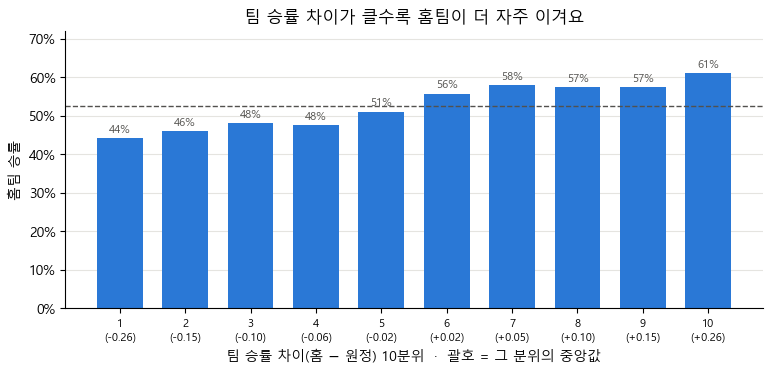

1분위 44.1% → 10분위 61.0% (차이 16.9%p)


In [15]:
wp = df.dropna(subset=["win_pct_diff"])
wp_dec = wp.groupby(pd.qcut(wp["win_pct_diff"], 10, labels=False))
wp_tbl = pd.DataFrame({"홈팀 승률": wp_dec["y"].mean(), "중앙값": wp_dec["win_pct_diff"].median()})

fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.bar(wp_tbl.index + 1, wp_tbl["홈팀 승률"], color=BLUE, width=0.7)
ax.axhline(home_rate, color=INK, linestyle="--", linewidth=1)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in wp_tbl["홈팀 승률"]], fontsize=8, color=INK, padding=2)
ax.set_xticks(wp_tbl.index + 1, [f"{int(i) + 1}\n({m:+.2f})" for i, m in zip(wp_tbl.index, wp_tbl["중앙값"])], fontsize=8)
ax.set(title="팀 승률 차이가 클수록 홈팀이 더 자주 이겨요", ylabel="홈팀 승률", ylim=(0, 0.72),
       xlabel="팀 승률 차이(홈 − 원정) 10분위  ·  괄호 = 그 분위의 중앙값")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.show()
print(f"1분위 {wp_tbl['홈팀 승률'].iloc[0]:.1%} → 10분위 {wp_tbl['홈팀 승률'].iloc[-1]:.1%} "
      f"(차이 {wp_tbl['홈팀 승률'].iloc[-1] - wp_tbl['홈팀 승률'].iloc[0]:.1%}p)")

**해석:** 홈팀 승률이 1분위 44%에서 10분위 61%까지 거의 계단처럼 올라가요. 승률이 높은 팀이 더 자주 이긴다는 당연한 사실이 데이터에서도 그대로 보여요.
다만 가장 극단적인 묶음도 61%에 그쳐요. 야구는 강팀도 10번 중 4번은 지는 종목이라, 승패 예측 정확도가 60% 안팎이면 잘한 편이라는 감을 잡을 수 있어요.

### 7-2. 선발 평균자책점 차이(`starter_era_diff`)

두 선발 모두 기록이 있는 경기(`starter_known = 1`, 8,150경기)만 써요.
**보는 법:** 왼쪽은 홈 선발의 ERA가 훨씬 **낮은**(= 홈 선발이 더 좋은) 경기, 오른쪽은 홈 선발 ERA가 훨씬 높은 경기예요. 그래서 이번에는 막대가 **내려가야** 정상이에요.

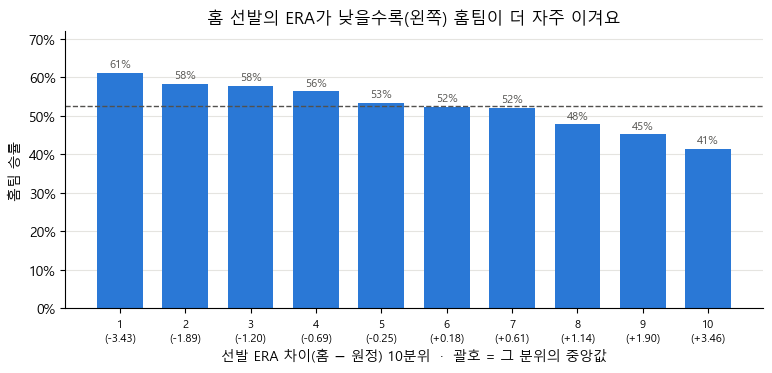

1분위 61.1% → 10분위 41.5% (차이 19.6%p)


In [16]:
sp = df[df["starter_known"] == 1]
sp_dec = sp.groupby(pd.qcut(sp["starter_era_diff"], 10, labels=False))
sp_tbl = pd.DataFrame({"홈팀 승률": sp_dec["y"].mean(), "중앙값": sp_dec["starter_era_diff"].median()})

fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.bar(sp_tbl.index + 1, sp_tbl["홈팀 승률"], color=BLUE, width=0.7)
ax.axhline(home_rate, color=INK, linestyle="--", linewidth=1)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in sp_tbl["홈팀 승률"]], fontsize=8, color=INK, padding=2)
ax.set_xticks(sp_tbl.index + 1, [f"{int(i) + 1}\n({m:+.2f})" for i, m in zip(sp_tbl.index, sp_tbl["중앙값"])], fontsize=8)
ax.set(title="홈 선발의 ERA가 낮을수록(왼쪽) 홈팀이 더 자주 이겨요", ylabel="홈팀 승률", ylim=(0, 0.72),
       xlabel="선발 ERA 차이(홈 − 원정) 10분위  ·  괄호 = 그 분위의 중앙값")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.show()
print(f"1분위 {sp_tbl['홈팀 승률'].iloc[0]:.1%} → 10분위 {sp_tbl['홈팀 승률'].iloc[-1]:.1%} "
      f"(차이 {sp_tbl['홈팀 승률'].iloc[0] - sp_tbl['홈팀 승률'].iloc[-1]:.1%}p)")

**해석:** 61%에서 41%까지 꾸준히 내려가요. 양 끝의 차이(약 20%p)가 팀 승률 차이(약 17%p)보다도 커서, **오늘의 선발이 누구냐**가 시즌 성적만큼, 혹은 그 이상으로 중요한 정보라는 걸 알 수 있어요. 선발 피처를 따로 공들여 만든 이유예요.

### 7-3. 휴식일 차이(`rest_diff`)

휴식일 차이는 10분위로 나눌 수 없어요. 경기의 93%가 0(두 팀의 마지막 경기 날짜가 같음)이라 10개 묶음으로 쪼갤 수가 없거든요. 그래서 값 그대로 묶었어요(−2 이하, −1, 0, +1, +2 이상).
**보는 법:** 막대 위는 홈팀 승률, 막대 아래 괄호는 그 묶음의 경기 수예요. 경기 수가 적은 묶음은 우연에 크게 흔들린다는 걸 함께 보세요.

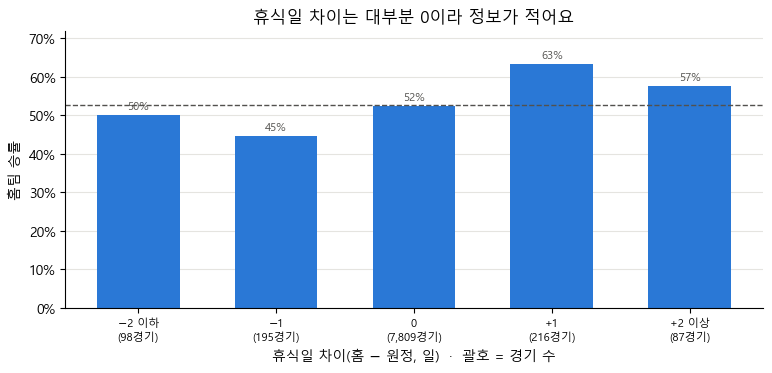

휴식일 차이가 0인 경기: 92.9%


In [17]:
rest = df.dropna(subset=["rest_diff"])
rest_grp = rest.groupby(rest["rest_diff"].clip(-2, 2))["y"].agg(["mean", "size"])
rest_names = {-2: "−2 이하", -1: "−1", 0: "0", 1: "+1", 2: "+2 이상"}

fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.bar(range(len(rest_grp)), rest_grp["mean"], color=BLUE, width=0.6)
ax.axhline(home_rate, color=INK, linestyle="--", linewidth=1)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in rest_grp["mean"]], fontsize=8, color=INK, padding=2)
ax.set_xticks(range(len(rest_grp)), [f"{rest_names[int(v)]}\n({n:,}경기)" for v, n in rest_grp["size"].items()], fontsize=8)
ax.set(title="휴식일 차이는 대부분 0이라 정보가 적어요", ylabel="홈팀 승률", ylim=(0, 0.72),
       xlabel="휴식일 차이(홈 − 원정, 일)  ·  괄호 = 경기 수")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.show()
print(f"휴식일 차이가 0인 경기: {(rest['rest_diff'] == 0).mean():.1%}")

**해석:** 홈팀이 하루 더 쉬고 나온 경기(+1, 216경기)는 홈팀 승률이 63%로 높고, 원정팀이 하루 더 쉰 경기(−1, 195경기)는 45%로 낮아요. "더 쉰 팀이 유리하다"는 방향은 맞아 보여요.
하지만 휴식일이 다른 경기는 전체의 7% 정도이고 묶음마다 경기 수가 적어서(200경기 안팎), 우연일 수도 있어요. 나머지 93%의 경기에서는 이 피처가 아무 정보도 주지 못해요.
그래서 휴식일은 **"있으면 조금 보탬이 될 수도 있는" 약한 피처**로 보고, 실제로 얼마나 쓸모 있는지는 다음 노트북에서 모델이 판단하게 할게요.

## 8. 파일로 저장하고 지문(SHA256) 확인

마지막으로 데이터셋을 `data/processed/features.parquet`에 저장해요. **parquet**는 표를 열 단위로 압축해 저장하는 파일 형식이라 CSV보다 작고 빠르며, 숫자 타입(정수·소수·빈 값)이 그대로 보존돼요.
명령줄에서 `python -m kbo_predict.features --out data/processed/features.parquet`를 실행해도 똑같은 파일이 같은 경로에 만들어져요(이 폴더는 Git에 올리지 않아요).

그리고 파일의 **SHA256**을 계산해요. SHA256은 파일 내용으로 만든 64자리 **지문**이에요. 파일이 한 바이트만 달라져도 완전히 다른 값이 나와요.
모델을 학습할 때 쓴 파일의 지문은 `models/manifest.json`의 `features_sha256`에 적혀 있어요. 두 지문이 같으면 **이 노트북이 만든 데이터 = 모델이 실제로 배운 데이터**라는 증거예요.

**출력 보는 법:** ✅ 줄이 나오면 노트북과 학습 파이프라인이 바이트 하나까지 같은 데이터를 만든 거예요. 다르면 ❌가 나오고 셀이 오류로 멈춰요.

In [18]:
out_path = ROOT / "data" / "processed" / "features.parquet"
features.save_features(df, out_path)
notebook_sha = features.features_sha256(out_path)

manifest = json.loads((ROOT / "models" / "manifest.json").read_text(encoding="utf-8"))
manifest_sha = manifest["features_sha256"]

print("저장한 파일           :", out_path.relative_to(ROOT).as_posix(), f"({out_path.stat().st_size / 1e6:.1f} MB)")
print("노트북이 만든 SHA256  :", notebook_sha)
print("manifest.json의 SHA256:", manifest_sha)
if notebook_sha == manifest_sha:
    print("✅ 같아요! 노트북이 만든 피처 = 모델이 학습한 피처")
else:
    print("❌ 달라요! 원본 데이터나 features.py가 모델 학습 이후에 바뀌었어요")
assert notebook_sha == manifest_sha

저장한 파일           : data/processed/features.parquet (1.4 MB)
노트북이 만든 SHA256  : 47c1d961f080f250350a7b5ef084844b3c4e8ac07c4cab917c8a84eee2752e1e
manifest.json의 SHA256: 47c1d961f080f250350a7b5ef084844b3c4e8ac07c4cab917c8a84eee2752e1e
✅ 같아요! 노트북이 만든 피처 = 모델이 학습한 피처


## 9. 요약과 다음 이야기

### 오늘 확인한 것
- 피처는 **그 경기 날짜의 전날까지** 끝난 경기로만 만들어요. 더블헤더 2차전에도 1차전 결과를 넣지 않아요. 규칙을 어기면 피처가 어떻게 오염되는지도 직접 봤어요.
- `LeagueState`는 경기가 끝날 때마다 팀·투수 기록을 쌓는 장부이고, 개막전처럼 아직 계산할 수 없는 값은 0이 아니라 빈 값(NaN)으로 둬요.
- 경기마다 **피처 26개**(팀 19개 + 선발투수 7개)를 만들어요. 박스스코어에 2루타·3루타·희생플라이가 없어서 OPS 대신 근사 출루율과 홈런 비율을 썼고, 구장·요일은 홈팀 정보와 겹쳐서 뺐어요.
- 선발투수 피처는 올 시즌 + 지난 시즌 기록을 합쳐 계산해요. 학습은 실제 선발, 라이브는 예고 선발을 쓰는 차이가 있어서, 백테스트 성적은 "선발이 확정된 상태" 기준이에요.
- 2015~2026년 **8,465경기**(정규시즌 FINAL − 무승부)의 데이터셋을 만들었고, 홈팀 승률은 52.6%예요.
- 팀 승률 차이와 선발 ERA 차이는 홈팀 승률과 뚜렷한 관계가 있고(양 끝 차이 약 17~20%p), 휴식일 차이는 약한 신호예요.
- 노트북이 저장한 파일의 SHA256이 `models/manifest.json`과 같아서, 이 데이터가 모델이 실제로 학습한 데이터와 똑같다는 걸 확인했어요.

### 다음 노트북: 03. 승패 예측 모델
이제 재료가 준비됐어요. 다음 노트북에서는 이 26개 피처로 **로지스틱 회귀**와 **LightGBM** 두 모델을 학습하고, 2026 시즌으로 성적을 매겨요.
"무조건 홈팀", "승률 높은 팀", "선발 ERA 낮은 팀" 같은 단순한 찍기 방법보다 얼마나 나은지, 그리고 선발 피처를 뺐을 때는 어떻게 되는지도 비교해 볼게요.